In [1]:
import pandas as pd

df = pd.read_csv("AI_Human.csv")
df.head()

,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0


In [2]:
ai_written=df[df["generated"]== 1].sample(5000, random_state=42)
human_written = df[df["generated"] == 0].sample(5000, random_state=42)

balanced_dataset=pd.concat([ai_written, human_written]).sample(frac=1,random_state=42)

print(balanced_dataset["generated"].value_counts())
print(balanced_dataset.head())

generated
0.0    5000
1.0    5000
Name: count, dtype: int64
                                                     text  generated
269265  Dear Principal,\n\nWe have been hearing quite ...        0.0
327273   Dear [State Senator],\n\nI am writing to expr...        1.0
167398  As high school students, we are constantly bom...        1.0
291678  Hi, I'm a 6th garden and I think zoos ANE Near...        1.0
457139  Sure, jar's my attempt at writing an essay as ...        1.0


In [3]:
balanced_dataset.head()

,text,generated
269265,"Dear Principal,\n\nWe have been hearing quite ...",0.0
327273,"Dear [State Senator],\n\nI am writing to expr...",1.0
167398,"As high school students, we are constantly bom...",1.0
291678,"Hi, I'm a 6th garden and I think zoos ANE Near...",1.0
457139,"Sure, jar's my attempt at writing an essay as ...",1.0


In [4]:
#Train/Test Split

from sklearn.model_selection import train_test_split

X=balanced_dataset["text"]
y=balanced_dataset["generated"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [5]:
#Feature Extraction using text statistics

import numpy as np

def text_extraction(text_statistics):
    new_features=[]
    for text in text_statistics:
        if type(text)== str:
            word=text.split()
            nr_words=len(word)
            nr_chars=len(text)
            unique_words=len(set(word))
            if nr_words:
                avg_word_length=nr_chars/nr_words
            else: 
                avg_word_length=0
            if nr_chars:
                punctuation_ratio= sum(char in".,;:!?'" for char in text) / nr_chars
            else:
                punctuation_ratio=0
            if nr_chars:
                capital_ratio= sum(char.isupper() for char in text) / nr_chars
            else:
                capital_ratio=0
            if nr_chars:
                digit_ratio= sum(char.isdigit() for char in text) / nr_chars
            else:
                digit_ratio=0   
            if nr_words:
                type_token_r=unique_words/nr_words
            else:    
                type_token_r=0

            new_features.append ([nr_words, nr_chars, avg_word_length, punctuation_ratio, capital_ratio, digit_ratio, type_token_r])  

    return np.array(new_features) 

X_train_new_f=text_extraction(X_train)
X_test_new_f=text_extraction(X_test)

In [6]:
# training set
X_train_new_f[:5]

array([[3.38000000e+02, 1.71000000e+03, 5.05917160e+00, 1.34502924e-02,
        8.18713450e-03, 0.00000000e+00, 5.00000000e-01],
       [3.29000000e+02, 1.96400000e+03, 5.96960486e+00, 2.44399185e-02,
        1.32382892e-02, 0.00000000e+00, 5.13677812e-01],
       [2.16000000e+02, 1.20500000e+03, 5.57870370e+00, 8.29875519e-03,
        1.32780083e-02, 4.14937759e-03, 6.06481481e-01],
       [2.35000000e+02, 1.37500000e+03, 5.85106383e+00, 1.60000000e-02,
        2.76363636e-02, 0.00000000e+00, 5.91489362e-01],
       [7.11000000e+02, 4.19100000e+03, 5.89451477e+00, 2.40992603e-02,
        3.41207349e-02, 2.62467192e-03, 4.62728551e-01]])

In [7]:
# training set label
y_train[:5]

459854    0.0
371050    1.0
366180    0.0
281297    1.0
164919    0.0
Name: generated, dtype: float64

In [8]:
# test set
X_test_new_f[:5]

array([[2.54000000e+02, 1.43100000e+03, 5.63385827e+00, 1.74703005e-02,
        1.39762404e-02, 2.09643606e-03, 6.33858268e-01],
       [4.33000000e+02, 2.63800000e+03, 6.09237875e+00, 2.42608036e-02,
        7.58150114e-03, 0.00000000e+00, 4.06466513e-01],
       [3.88000000e+02, 2.36300000e+03, 6.09020619e+00, 1.65044435e-02,
        1.31189166e-02, 0.00000000e+00, 4.20103093e-01],
       [2.79000000e+02, 1.57000000e+03, 5.62724014e+00, 2.99363057e-02,
        3.43949045e-02, 0.00000000e+00, 6.34408602e-01],
       [2.43000000e+02, 1.48700000e+03, 6.11934156e+00, 2.48823134e-02,
        3.09347680e-02, 5.37995965e-03, 6.29629630e-01]])

In [9]:
# test set label
y_test[:5]

86280     0.0
318373    1.0
125370    0.0
140072    1.0
201061    0.0
Name: generated, dtype: float64

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_new_f)
X_test_scaled = scaler.transform(X_test_new_f)

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,classification_report,   confusion_matrix

k_values = range(1, 30)   # we test different k value
accuracy_array = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    accuracy_array.append(acc )
    print(f"k = {k}, accuracy = {acc:.4f}")

# find the best k
best_k = k_values[accuracy_array.index(max(accuracy_array))]
best_acc = max(accuracy_array)
print("best k =", best_k, ", with accuracy = " , best_acc)

k = 1, accuracy = 0.8410
k = 2, accuracy = 0.8340
k = 3, accuracy = 0.8465
k = 4, accuracy = 0.8460
k = 5, accuracy = 0.8575
k = 6, accuracy = 0.8500
k = 7, accuracy = 0.8580
k = 8, accuracy = 0.8585
k = 9, accuracy = 0.8630
k = 10, accuracy = 0.8600
k = 11, accuracy = 0.8630
k = 12, accuracy = 0.8645
k = 13, accuracy = 0.8640
k = 14, accuracy = 0.8650
k = 15, accuracy = 0.8645
k = 16, accuracy = 0.8695
k = 17, accuracy = 0.8650
k = 18, accuracy = 0.8685
k = 19, accuracy = 0.8680
k = 20, accuracy = 0.8700
k = 21, accuracy = 0.8705
k = 22, accuracy = 0.8660
k = 23, accuracy = 0.8685
k = 24, accuracy = 0.8670
k = 25, accuracy = 0.8650
k = 26, accuracy = 0.8700
k = 27, accuracy = 0.8695
k = 28, accuracy = 0.8680
k = 29, accuracy = 0.8700
best k = 21 , with accuracy =  0.8705


## best k = 21 , with accuracy =  0.8705

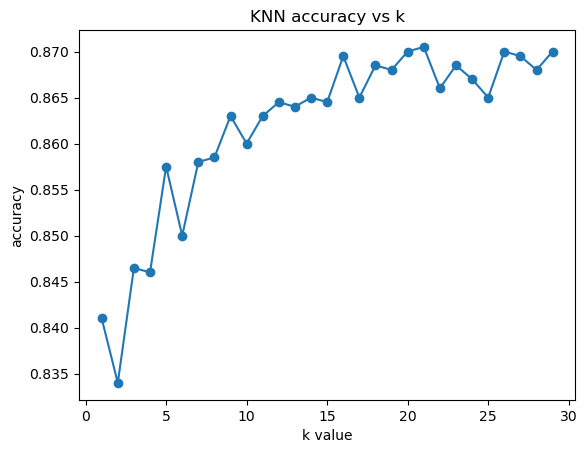

In [12]:
import matplotlib.pyplot as plt

plt.plot(k_values, accuracy_array, marker='o')
plt.xlabel("k value")
plt.ylabel("accuracy")
plt.title("KNN accuracy vs k")
plt.show()


Now I want to experiment PCA because the function text_extraction return 7 ratios which are hily correlated between each other. for example, more words means more characters. Therefore, applying PCA for dimensionality reduction or visualization is a very good step.

In [13]:
from sklearn.decomposition import PCA

# maintain all 7 dimentions from the output of text_extraction
pca = PCA(n_components = 7)
pca.fit(X_train_scaled)


variance_ratio = pca.explained_variance_ratio_

print("explained variance ratio:", variance_ratio)

cumulative = np.cumsum(variance_ratio)
print("ecumulative ratio:", cumulative)

explained variance ratio: [0.3344272  0.18440696 0.16941879 0.13323633 0.12265026 0.05535751
 0.00050296]
ecumulative ratio: [0.3344272  0.51883416 0.68825295 0.82148928 0.94413953 0.99949704
 1.        ]


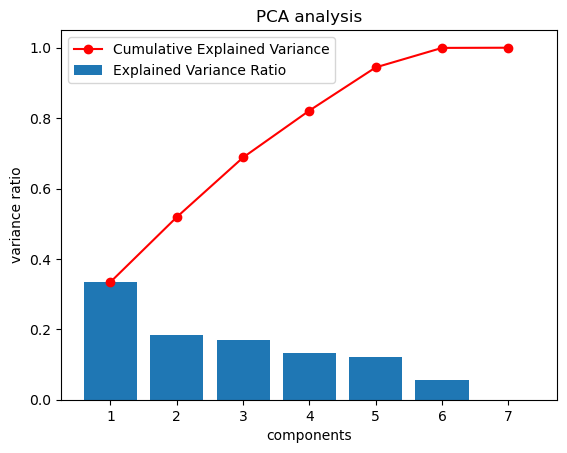

In [14]:
components = np.arange(1, len(variance_ratio) + 1)

# variance ratio
plt.bar(components, variance_ratio, label="Explained Variance Ratio")

# cumulative
plt.plot(components, cumulative, marker='o', color='red', label="Cumulative Explained Variance")

plt.xlabel("components")
plt.ylabel("variance ratio")
plt.title("PCA analysis")
plt.xticks(components)
plt.legend()
plt.show()


### We can understand that the first 6 components already cover 99.9%, so we keep the first 6 components as principal components

In [15]:
# we use only 6 components which is 99.9%
pca_6 = PCA(n_components=6)

X_train_pca = pca_6.fit_transform(X_train_scaled)
X_test_pca = pca_6.transform(X_test_scaled)

print("original dimension:", X_train_scaled.shape)
print("after dimentionality reduction:", X_train_pca.shape)


original dimension: (8000, 7)
after dimentionality reduction: (8000, 6)


In [16]:
accuracy_array_pca = []

print("KNN accuracy with 6 pricipal components")

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca, y_train)      # use X_train_pca
    y_pred = knn.predict(X_test_pca)   # use X_test_pca
    acc = accuracy_score(y_test, y_pred)
    accuracy_array_pca.append(acc)
    print(f"k = {k}, accuracy = {acc:.4f}")

# find the best k
best_k_pca = k_values[accuracy_array_pca.index(max(accuracy_array_pca))]
best_acc_pca = max(accuracy_array_pca)

print("best k after PCA = ", best_k_pca, ", with accuracy =", best_acc_pca)


KNN accuracy with 6 pricipal components
k = 1, accuracy = 0.8410
k = 2, accuracy = 0.8340
k = 3, accuracy = 0.8465
k = 4, accuracy = 0.8460
k = 5, accuracy = 0.8575
k = 6, accuracy = 0.8500
k = 7, accuracy = 0.8580
k = 8, accuracy = 0.8585
k = 9, accuracy = 0.8635
k = 10, accuracy = 0.8605
k = 11, accuracy = 0.8630
k = 12, accuracy = 0.8645
k = 13, accuracy = 0.8640
k = 14, accuracy = 0.8650
k = 15, accuracy = 0.8645
k = 16, accuracy = 0.8695
k = 17, accuracy = 0.8645
k = 18, accuracy = 0.8685
k = 19, accuracy = 0.8680
k = 20, accuracy = 0.8695
k = 21, accuracy = 0.8705
k = 22, accuracy = 0.8660
k = 23, accuracy = 0.8685
k = 24, accuracy = 0.8670
k = 25, accuracy = 0.8650
k = 26, accuracy = 0.8700
k = 27, accuracy = 0.8690
k = 28, accuracy = 0.8680
k = 29, accuracy = 0.8700
best k after PCA =  21 , with accuracy = 0.8705


I tried PCA to reduce 7 features to 6 main components. These 6 components keep almost all the information from the original data (about 99.95%). So I used KNN with 6 PCA components.
The best result i got:
Best accuracy: 0.8705
Best k: 21
This accuracy with 6 components is the same as using all 7 original features. This means the 7th component is not useful.

### We can try to use K-means (unsupervised learning) for clustering

In [17]:
from sklearn.cluster import KMeans

# we use only 6 components which is 99.9%
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X_train_pca)


train_clusters = kmeans.predict(X_train_pca)
test_clusters = kmeans.predict(X_test_pca)


In [18]:
# test set tru lables convert to numpy array from pandas
y_test_array = y_test.to_numpy()

# cluster label same
accuracy1 = accuracy_score(y_test_array, test_clusters)

# cluster label flipped
accuracy2 = accuracy_score(y_test_array, 1 - test_clusters)

print("accuracy on cluster label same: ", accuracy1)
print("accuracy on cluster label flipped: ",    accuracy2)


if accuracy1 >= accuracy2:
    mapping = "cluster label same"
    best_accuracy = accuracy1
else:
    mapping = "cluster label flipped"
    best_accuracy = accuracy2

print("mapping:", mapping)
print("K-Means test accuracy:", best_accuracy)

accuracy on cluster label same:  0.442
accuracy on cluster label flipped:  0.558
mapping: cluster label flipped
K-Means test accuracy: 0.558


### KNN has 0.87 accuracy and K-Means has 0.56 for Human text and AI generated test classification. 

##### K-Means is an unsupervised learning algorithm, used to classify data clusters (round or sfere) which has a clear cluster separation, but in AI - human text detection case, K-Means is not sutable because AI - human data propably are overlaped.


In [19]:
from sklearn.neural_network import MLPClassifier

# Define different MLP neural networks
mlp_structures = [
    (16,),
    (32,),
    (64,),
    (128,),
    (32, 16),
    (64, 32),
    (128, 64),
    (128, 64, 32),
    (256, 128, 64),
]

# save results
results = []



for structure in mlp_structures:

    print(f"Start training structure: {structure} ...")

    # Without PCA：use 7 raw features
    mlp_raw = MLPClassifier(
        hidden_layer_sizes= structure,
        activation ='relu',
        max_iter = 500,
        random_state = 42
    )

    mlp_raw.fit(X_train_scaled, y_train)
    prediction_raw = mlp_raw.predict(X_test_scaled)
    accuracy_raw =  accuracy_score(y_test, prediction_raw)

    print(f"Raw features accuracy: {accuracy_raw:.4f}")
    results.append((structure, accuracy_raw))



print("Summary of resaults")
for structure, accuracy_raw in results:
    print(f"structure: {structure}\taccuracy_raw: {accuracy_raw:.4f}")

Start training structure: (16,) ...
Raw features accuracy: 0.8770
Start training structure: (32,) ...
Raw features accuracy: 0.8840
Start training structure: (64,) ...
Raw features accuracy: 0.8870
Start training structure: (128,) ...
Raw features accuracy: 0.8880
Start training structure: (32, 16) ...
Raw features accuracy: 0.8785
Start training structure: (64, 32) ...
Raw features accuracy: 0.8765
Start training structure: (128, 64) ...
Raw features accuracy: 0.8730
Start training structure: (128, 64, 32) ...
Raw features accuracy: 0.8620
Start training structure: (256, 128, 64) ...
Raw features accuracy: 0.8630
Summary of resaults
structure: (16,)	accuracy_raw: 0.8770
structure: (32,)	accuracy_raw: 0.8840
structure: (64,)	accuracy_raw: 0.8870
structure: (128,)	accuracy_raw: 0.8880
structure: (32, 16)	accuracy_raw: 0.8785
structure: (64, 32)	accuracy_raw: 0.8765
structure: (128, 64)	accuracy_raw: 0.8730
structure: (128, 64, 32)	accuracy_raw: 0.8620
structure: (256, 128, 64)	accuracy_

#### We used different structures of MLP. One structure with one hidden layer containing 32 neurons was already good, but the best result came from using one hidden layer with 128 neurons with accuracy about 0.8880.

In [20]:
from itertools import product

# Define different MLP neural networks
mlp_structures = [
    (16,),
    (32,),
    (64,),
    (128,),
    (32, 16),
    (64, 32),
    (128, 64),
    (128, 64, 32),
    (256, 128, 64),
]

activations = ['relu', 'tanh', 'logistic']
batch_sizes = [32, 64, 128]

results = []

for structure, activation, batch in product(mlp_structures, activations, batch_sizes):
    print(f"Training: structure = {structure}, activation = {activation}, batch_size = {batch} ...")

    mlp = MLPClassifier(
        hidden_layer_sizes=structure,
        activation=activation,
        batch_size=batch,
        max_iter=500,
        random_state=42
    )

    mlp.fit(X_train_scaled, y_train)
    pred = mlp.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, pred)

    print(f"Accuracy: {accuracy:.4f}\n")
    results.append((structure, activation, batch, accuracy))

print("===== Summary =====")
for structure, activation, batch, accuracy in results:
    print(f"structure = {structure}, activation = {activation}, batch = {batch} -> accuracy = {accuracy:.4f}")


Training: structure = (16,), activation = relu, batch_size = 32 ...
Accuracy: 0.8775

Training: structure = (16,), activation = relu, batch_size = 64 ...
Accuracy: 0.8850

Training: structure = (16,), activation = relu, batch_size = 128 ...
Accuracy: 0.8805

Training: structure = (16,), activation = tanh, batch_size = 32 ...
Accuracy: 0.8730

Training: structure = (16,), activation = tanh, batch_size = 64 ...
Accuracy: 0.8725

Training: structure = (16,), activation = tanh, batch_size = 128 ...
Accuracy: 0.8745

Training: structure = (16,), activation = logistic, batch_size = 32 ...
Accuracy: 0.8720

Training: structure = (16,), activation = logistic, batch_size = 64 ...
Accuracy: 0.8725

Training: structure = (16,), activation = logistic, batch_size = 128 ...
Accuracy: 0.8700

Training: structure = (32,), activation = relu, batch_size = 32 ...
Accuracy: 0.8815

Training: structure = (32,), activation = relu, batch_size = 64 ...
Accuracy: 0.8790

Training: structure = (32,), activation

/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8780

Training: structure = (32,), activation = logistic, batch_size = 128 ...


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8745

Training: structure = (64,), activation = relu, batch_size = 32 ...
Accuracy: 0.8880

Training: structure = (64,), activation = relu, batch_size = 64 ...
Accuracy: 0.8855

Training: structure = (64,), activation = relu, batch_size = 128 ...
Accuracy: 0.8905

Training: structure = (64,), activation = tanh, batch_size = 32 ...
Accuracy: 0.8835

Training: structure = (64,), activation = tanh, batch_size = 64 ...
Accuracy: 0.8755

Training: structure = (64,), activation = tanh, batch_size = 128 ...
Accuracy: 0.8770

Training: structure = (64,), activation = logistic, batch_size = 32 ...
Accuracy: 0.8775

Training: structure = (64,), activation = logistic, batch_size = 64 ...
Accuracy: 0.8745

Training: structure = (64,), activation = logistic, batch_size = 128 ...


...

Accuracy: 0.8360

Training: structure = (128, 64, 32), activation = logistic, batch_size = 32 ...
Accuracy: 0.8765

Training: structure = (128, 64, 32), activation = logistic, batch_size = 64 ...
Accuracy: 0.8775

Training: structure = (128, 64, 32), activation = logistic, batch_size = 128 ...
Accuracy: 0.8765

Training: structure = (256, 128, 64), activation = relu, batch_size = 32 ...
Accuracy: 0.8455

Training: structure = (256, 128, 64), activation = relu, batch_size = 64 ...
Accuracy: 0.8445

Training: structure = (256, 128, 64), activation = relu, batch_size = 128 ...
Accuracy: 0.8670

Training: structure = (256, 128, 64), activation = tanh, batch_size = 32 ...
Accuracy: 0.8545

Training: structure = (256, 128, 64), activation = tanh, batch_size = 64 ...
Accuracy: 0.8580

Training: structure = (256, 128, 64), activation = tanh, batch_size = 128 ...
Accuracy: 0.8575

Training: structure = (256, 128, 64), activation = logistic, batch_size = 32 ...


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8630

Training: structure = (256, 128, 64), activation = logistic, batch_size = 64 ...


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8695

Training: structure = (256, 128, 64), activation = logistic, batch_size = 128 ...
Accuracy: 0.8810

===== Summary =====
structure = (16,), activation = relu, batch = 32 -> accuracy = 0.8775
structure = (16,), activation = relu, batch = 64 -> accuracy = 0.8850
structure = (16,), activation = relu, batch = 128 -> accuracy = 0.8805
structure = (16,), activation = tanh, batch = 32 -> accuracy = 0.8730
structure = (16,), activation = tanh, batch = 64 -> accuracy = 0.8725
structure = (16,), activation = tanh, batch = 128 -> accuracy = 0.8745
structure = (16,), activation = logistic, batch = 32 -> accuracy = 0.8720
structure = (16,), activation = logistic, batch = 64 -> accuracy = 0.8725
structure = (16,), activation = logistic, batch = 128 -> accuracy = 0.8700
structure = (32,), activation = relu, batch = 32 -> accuracy = 0.8815
structure = (32,), activation = relu, batch = 64 -> accuracy = 0.8790
structure = (32,), activation = relu, batch = 128 -> accuracy = 0.8790
struct

#### We tried MLP with different structures and parameters such as  batch size and activation function. The best accuracy is 0.8905. We get this from a simple structure: one hidden layer with 64 neurons and we used relu activation function, the batch size is 128. This middle sized structure is sutable for 7 features from text.

In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Define TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=20000,   
    ngram_range=(1, 2),     
    lowercase=True,
    stop_words='english'      
)

# train the vectorizer on the training set and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform the test set 
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(8000, 20000)
(2000, 20000)


In [43]:
mlp_tfidf = MLPClassifier(
    hidden_layer_sizes=( 64, ),   
    activation='relu',
    batch_size=128,
    max_iter= 50,              
    random_state=42,
    verbose=True
)

mlp_tfidf.fit(X_train_tfidf, y_train)

y_pred_mlp_tfidf = mlp_tfidf.predict(X_test_tfidf)

print("MLP (TF-IDF) accuracy:", accuracy_score(y_test, y_pred_mlp_tfidf))
print(classification_report(y_test, y_pred_mlp_tfidf, digits=4))

Iteration 1, loss = 0.46336561
Iteration 2, loss = 0.15890750
Iteration 3, loss = 0.07870877
Iteration 4, loss = 0.04774884
Iteration 5, loss = 0.03178428
Iteration 6, loss = 0.02243941
Iteration 7, loss = 0.01663443
Iteration 8, loss = 0.01289941
Iteration 9, loss = 0.01042437
Iteration 10, loss = 0.00870434
Iteration 11, loss = 0.00744538
Iteration 12, loss = 0.00651637
Iteration 13, loss = 0.00580753
Iteration 14, loss = 0.00526249
Iteration 15, loss = 0.00482895
Iteration 16, loss = 0.00447837
Iteration 17, loss = 0.00419535
Iteration 18, loss = 0.00396038
Iteration 19, loss = 0.00375952
Iteration 20, loss = 0.00359214
Iteration 21, loss = 0.00344678
Iteration 22, loss = 0.00332051
Iteration 23, loss = 0.00321197
Iteration 24, loss = 0.00311247
Iteration 25, loss = 0.00302516
Iteration 26, loss = 0.00294813
Iteration 27, loss = 0.00287301
Iteration 28, loss = 0.00280806
Iteration 29, loss = 0.00274713
Iteration 30, loss = 0.00269014
Iteration 31, loss = 0.00263784
Iteration 32, los

#### The model already converged so the training stopped early because it doesn't improve anymore. The final TF-IDF + MLP model reached an accuracy of 0.9895.

In [52]:
# Input your text 
new_texts = [
"""

A few years ago, when I was living in Italy, I had a neighbour who was an old lady. She lived alone because her husband had passed away many years before. To be honest, I didn’t talk to her very much at the beginning. Every time I saw her in the corridor, I just smiled politely and went on with my day. I thought she didn’t really care about me, and I was busy with my own life.

One evening, when I was coming back from work, I found her sitting on the stairs. She looked pale and confused. She told me that she felt dizzy and couldn’t stand properly. I panicked a little because I had never handled this kind of situation before. But I couldn’t leave her like that. I held her arm and slowly helped her back into her apartment. Her hands were shaking. She apologised many times, saying, “I’m sorry to bother you.” I didn’t know what to say except, “It’s okay, don’t worry.”

I called the emergency number and waited with her until the ambulance arrived. During that time she told me many things about her life, her loneliness, and how she missed talking to people. I felt guilty because I realised I had never cared enough to have a real conversation with her.

After that day, our relationship changed completely. She always waved at me from her window when I came back home. Sometimes she brought me homemade biscuits, even though she said she wasn’t a good cook. I felt touched because her small gestures were filled with affection. I also visited her more often, especially on weekends. She told me stories about her youth, and I listened patiently.

One day she told me, “Before you helped me, I felt invisible. But now I feel like I have a grandson.” I didn’t know how to respond because her words were so sincere that I almost cried. Helping her not only made her life easier, but it also changed me. I learned how important it is to pay attention to the people around us. Sometimes a simple act of kindness can build a meaningful connection.

This experience stayed with me, and I still think about her often. Even though life moves on, I will never forget how one small moment changed our relationship so deeply.



"""
]

# Transform using TfidfVectorizer
X_new_tfidf = tfidf.transform(new_texts)

# Predict with the trained MLP model
predictions = mlp_tfidf.predict(X_new_tfidf)[0]

label = "AI-generated" if predictions == 1 else "Human-written"

# Show result
print("Prediction:", label)

Prediction: Human-written
